# Anàlisi de Canvis de Torn (Nivell 1)
Aquest quadern respon a la pregunta: **Qui no és al seu torn?**

Compara el `torn_requerit` teòric de cada sessió amb l'hora d'inici real (`h_ini`). Considerem que el torn de matí és abans de les 14:30 i el de tarda a partir de les 14:30. Després agrupa les discrepàncies per `titulacions_curs` per identificar quines titulacions hauran de moure més sessions per adaptar-se al nou model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregar les dades
sessions = pd.read_csv('sessions.csv')

# 2. Determinar el torn actual segons l'hora d'inici
def get_real_shift(h):
    if pd.isna(h):
        return None
    return 'mati' if str(h) < '14:30' else 'tarda'

sessions['torn_actual'] = sessions['h_ini'].apply(get_real_shift)

print("Torns actuals calculats correctament.")


Torns actuals calculats correctament.


In [2]:
# 3. Filtrar les sessions desplaçades (fora del seu torn requerit)
# Ens quedem només amb aquelles que tenen un torn_requerit definit i vàlid ('mati' o 'tarda')
sessions_valides = sessions[sessions['torn_requerit'].isin(['mati', 'tarda'])].copy()

fora_de_torn = sessions_valides[sessions_valides['torn_requerit'] != sessions_valides['torn_actual']]

print(f"Total de sessions programades fora del seu torn teòric: {len(fora_de_torn)}")


Total de sessions programades fora del seu torn teòric: 6755


Top 10 Titulacions que haurien de canviar més sessions:


,titulacions_curs,sessions_desplaçades
14,GEI:3r|GEI:4t,1962
12,GEI:2n,598
11,GEI:1r,565
19,GEQ:3r,440
21,GEST:3r,377
7,GEET:3r|GEST:3r,356
13,GEI:3r,323
0,GCIS:2n,299
24,GIA:2n,259
15,GEI:4t,247


C:\Users\arnau\AppData\Local\Temp\ipykernel_8196\452632844.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=afectacio_titulacions.head(15), x='sessions_desplaçades', y='titulacions_curs', palette='viridis')


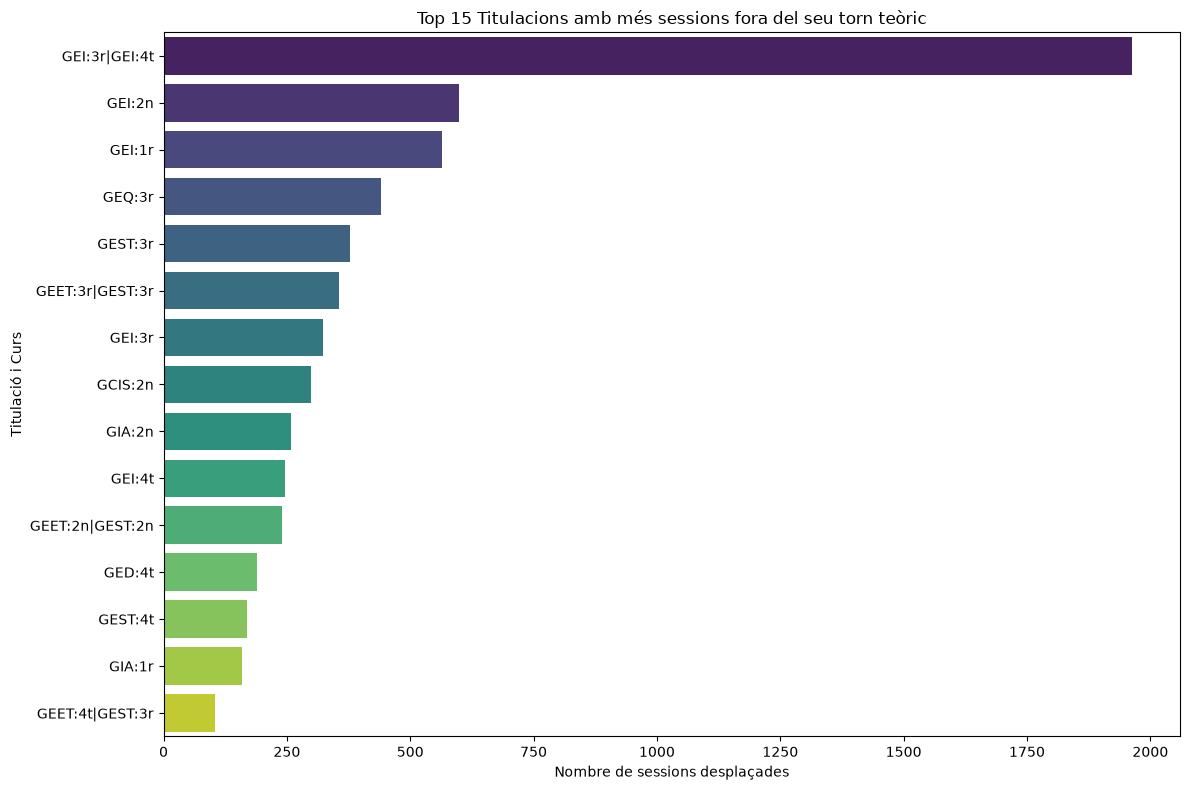

In [3]:
# 4. Agrupar per titulacions_curs per veure quines estan més afectades
afectacio_titulacions = fora_de_torn.groupby('titulacions_curs').size().reset_index(name='sessions_desplaçades')
afectacio_titulacions = afectacio_titulacions.sort_values(by='sessions_desplaçades', ascending=False)

print("Top 10 Titulacions que haurien de canviar més sessions:")
display(afectacio_titulacions.head(10))

# 5. Visualització
plt.figure(figsize=(12, 8))
sns.barplot(data=afectacio_titulacions.head(15), x='sessions_desplaçades', y='titulacions_curs', palette='viridis')
plt.title('Top 15 Titulacions amb més sessions fora del seu torn teòric')
plt.xlabel('Nombre de sessions desplaçades')
plt.ylabel('Titulació i Curs')
plt.tight_layout()
plt.show()
